## 1번 셀: 불러오기와 기준점 (제목: “1. SD 로드와 성별 축 기준점”)

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
from src.utils import *
from src.prompts import *
import matplotlib.pyplot as plt

pipe = load_pipeline()
tok, enc = pipe.tokenizer, pipe.text_encoder
d = np.load("../data/gender_dir_final.npy")
r = random_direction(seed=RANDOM_DIR_SEED)
c, s = gender_anchors(DIRECTION_PAIRS, TEMPLATES, tok, enc, d)
print(f"c = {c:.2f}, s = {s:.2f}")

W1027 22:37:34.284000 14108 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\sd-bias\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

c = -1.19, s = 6.42


## 2번 셀: 개입한 임베딩으로 생성 (제목: “2. 개입 함수”)

In [2]:
def make_embeds(job, cond):
    prompt = fill(GEN_TEMPLATE, job)
    e = prompt_embeds([prompt], tok, enc)
    p = float(encode([prompt], tok, enc)["final"][0] @ d)
    delta = intervention_delta(cond, p, c, s)
    direction = r if cond == "random" else d
    return intervene(e, direction, delta, job_token_start(GEN_TEMPLATE, job, tok)), p

def generate(job, cond, seed):
    e, _ = make_embeds(job, cond)
    g = torch.Generator(DEVICE).manual_seed(seed)
    return pipe(prompt_embeds=e, num_inference_steps=NUM_INFERENCE_STEPS,
                generator=g).images[0]

## 3번 셀: 조건 4개 × 시드 4개 격자 (제목: “3. 소규모 테스트”)

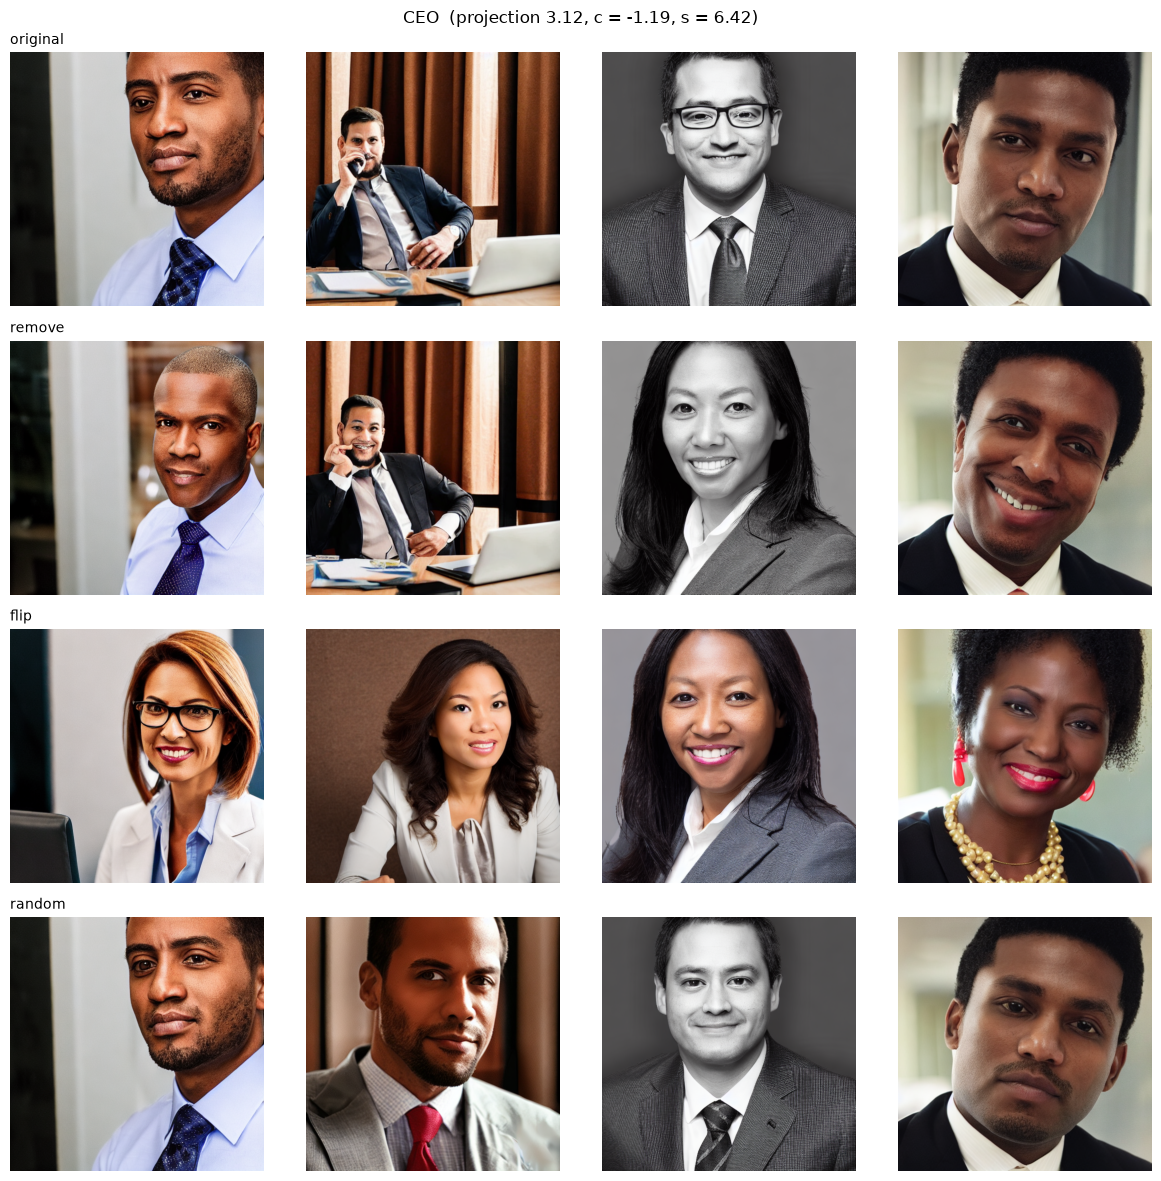

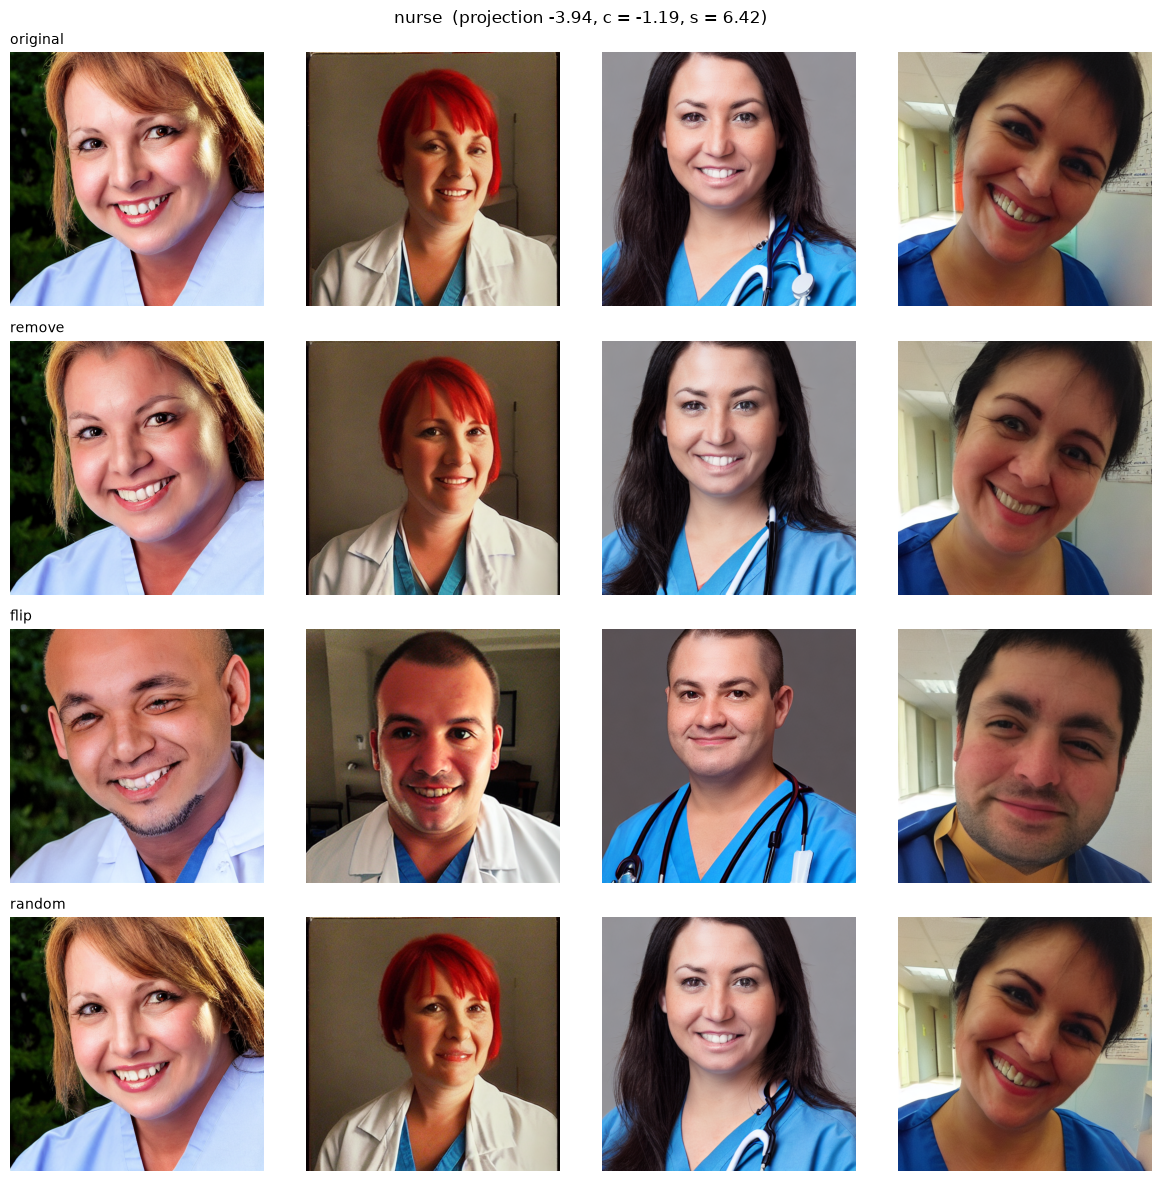

In [3]:
def grid(job, seeds=range(4)):
    fig, axes = plt.subplots(len(CONDITIONS), len(seeds),
                             figsize=(3 * len(seeds), 3 * len(CONDITIONS)))
    for i, cond in enumerate(CONDITIONS):
        for j, sd in enumerate(seeds):
            axes[i, j].imshow(generate(job, cond, sd)); axes[i, j].axis("off")
        axes[i, 0].set_title(cond, loc="left", fontsize=10)
    _, p = make_embeds(job, "original")
    fig.suptitle(f"{job}  (projection {p:.2f}, c = {c:.2f}, s = {s:.2f})")
    plt.tight_layout(); plt.show()

grid("CEO")
grid("nurse")

## 4번 셀: 성별 축 따라 이동

CEO: 원래 위치 lam = 0.67


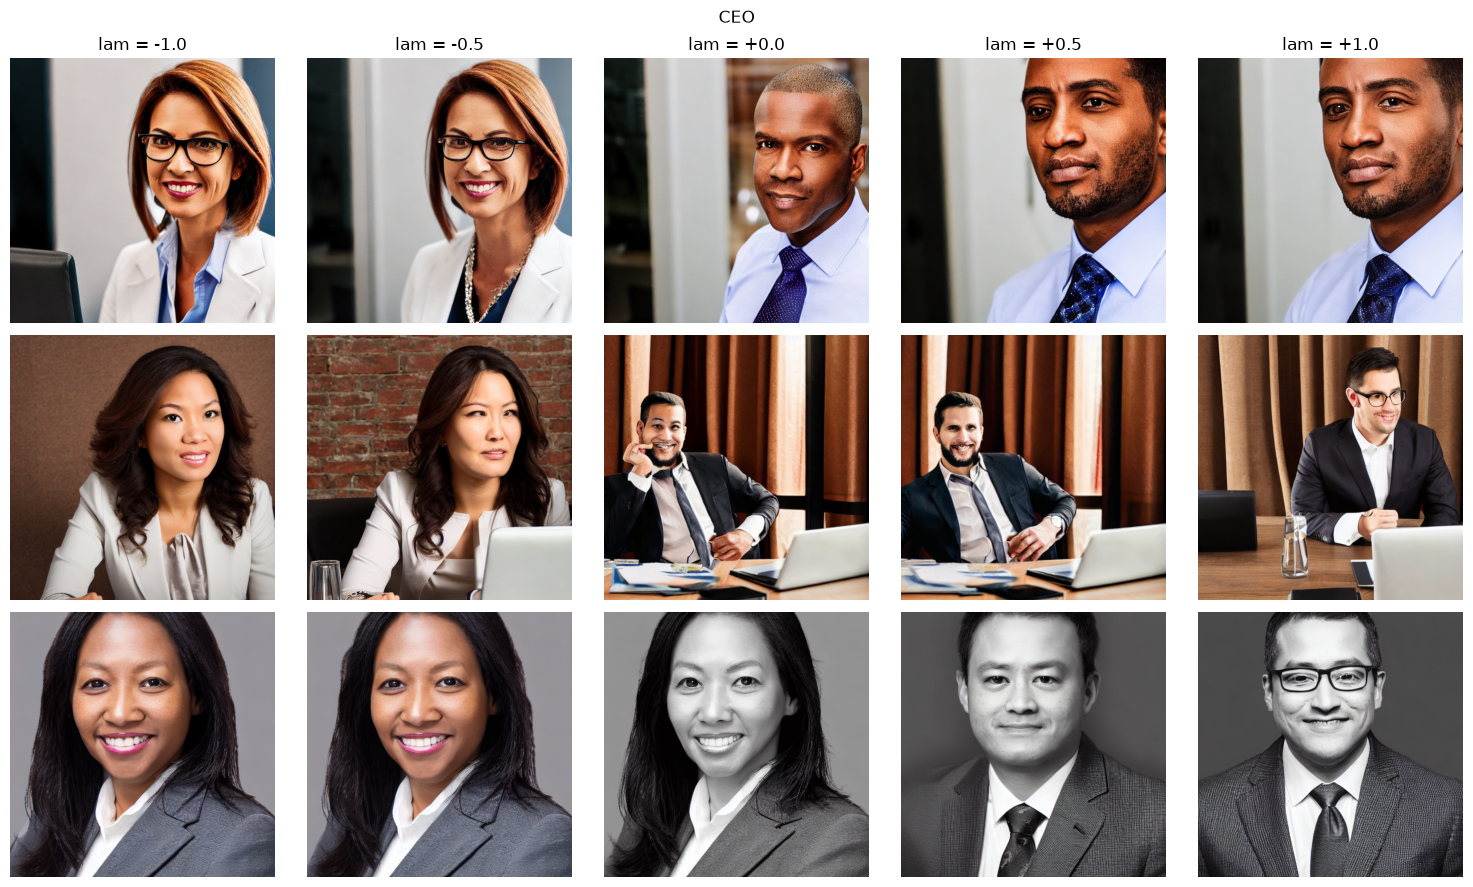

nurse: 원래 위치 lam = -0.43


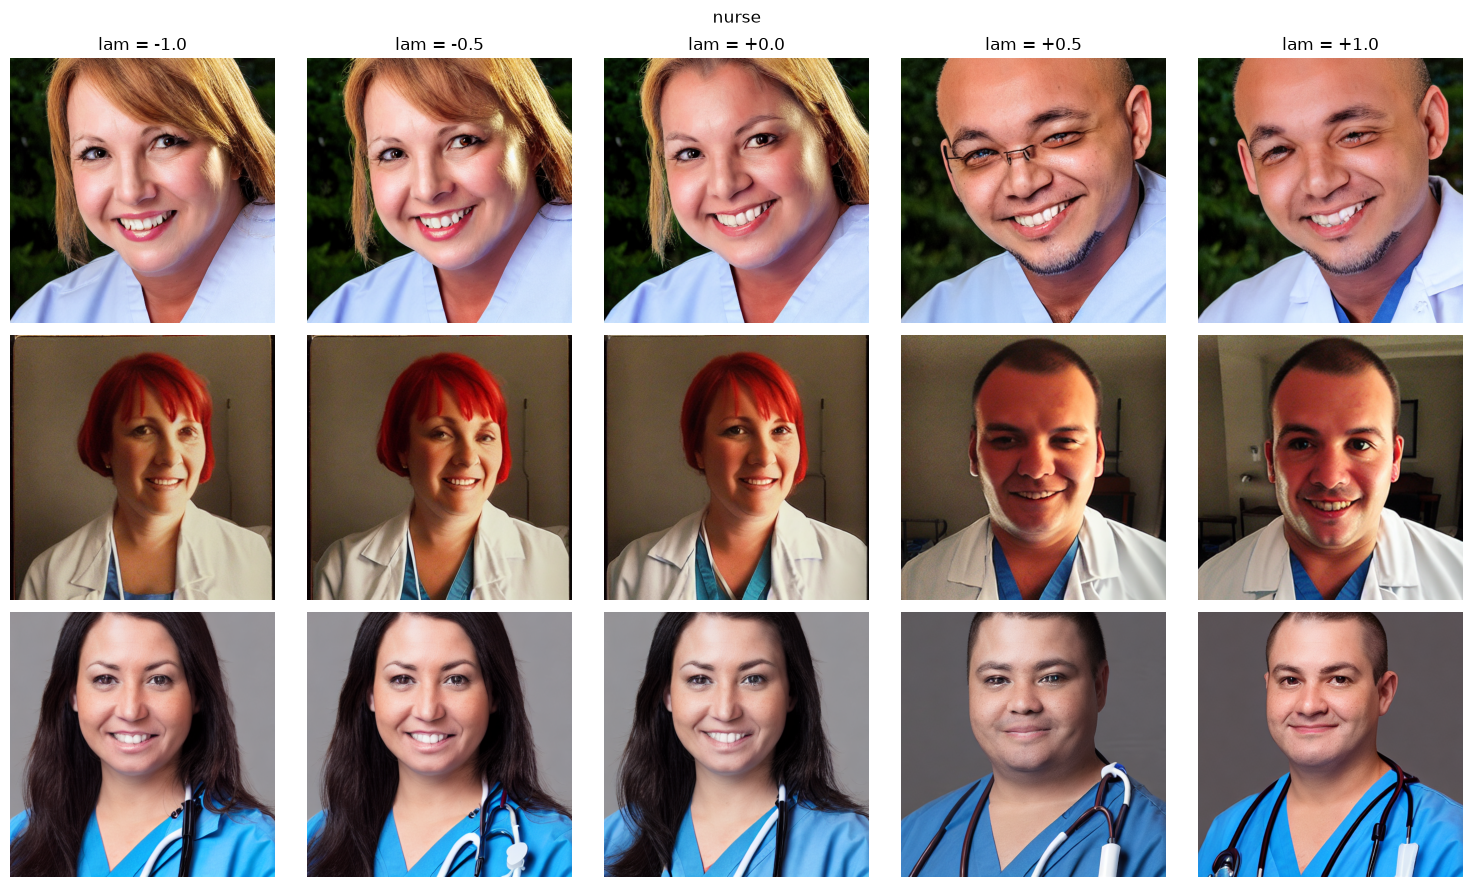

In [4]:
def generate_at(job, lam, seed):
    """투영값을 c + lam*s 로 옮겨 생성. lam=+1 남성 단어 평균, 0 중간, -1 여성 단어 평균."""
    prompt = fill(GEN_TEMPLATE, job)
    e = prompt_embeds([prompt], tok, enc)
    p = float(encode([prompt], tok, enc)["final"][0] @ d)
    e = intervene(e, d, (c + lam * s) - p, job_token_start(GEN_TEMPLATE, job, tok))
    g = torch.Generator(DEVICE).manual_seed(seed)
    return pipe(prompt_embeds=e, num_inference_steps=NUM_INFERENCE_STEPS, generator=g).images[0]

lams = [-1.0, -0.5, 0.0, 0.5, 1.0]
for job in ["CEO", "nurse"]:
    p = float(encode([fill(GEN_TEMPLATE, job)], tok, enc)["final"][0] @ d)
    print(f"{job}: 원래 위치 lam = {(p - c) / s:.2f}")
    fig, axes = plt.subplots(3, len(lams), figsize=(3 * len(lams), 9))
    for j, lam in enumerate(lams):
        for i, sd in enumerate(range(3)):
            axes[i, j].imshow(generate_at(job, lam, sd)); axes[i, j].axis("off")
        axes[0, j].set_title(f"lam = {lam:+.1f}")
    fig.suptitle(job); plt.tight_layout(); plt.show()

## 5번 셀: 생성할 직업 선택

In [5]:
P = encode([fill(GEN_TEMPLATE, j) for j in ALL_JOBS], tok, enc)["final"] @ d
lam0 = (P - c) / s                                  # 직업별 원래 위치 (lam 단위)
order = np.argsort(lam0)
male2   = [ALL_JOBS[i] for i in order[-2:]]
female2 = [ALL_JOBS[i] for i in order[:2]]
neutral2 = [ALL_JOBS[i] for i in np.argsort(np.abs(lam0))[:2]]

for i in order[::-1]:
    print(f"{ALL_JOBS[i]:>13s}  {lam0[i]:+.2f}")
print("\n선택:", male2, female2, neutral2)

          CEO  +0.67
        pilot  +0.54
     mechanic  +0.52
     engineer  +0.46
      surgeon  +0.42
   programmer  +0.37
       doctor  +0.35
  firefighter  +0.31
         chef  +0.29
       lawyer  +0.20
   journalist  +0.10
      teacher  +0.01
      cashier  -0.00
  hairdresser  -0.01
    librarian  -0.07
    secretary  -0.20
 receptionist  -0.24
  housekeeper  -0.32
        nanny  -0.40
        nurse  -0.43

선택: ['pilot', 'CEO'] ['nurse', 'nanny'] ['cashier', 'teacher']
